# Context, problem statement and objectives

**Auteurs :** Gwendal Lavolee et Karl Anthony Garozzo
**Formation :** EFREI — Projet de Machine Learning
**Données :** annonces Airbnb à Toronto, septembre 2020

## 1. Context, problem statement and objectives

We study Airbnb listings in Toronto using data collected in September 2020. We chose Toronto because we are currently studying there.

**Research question:** How do listing characteristics relate to nightly prices, and can we identify different types of rentals?

We will explore and clean the data, apply K-means and hierarchical clustering, predict prices using linear regression, and classify room types using KNN. Our conclusions concern September 2020, during the COVID-19 pandemic.

## 2. Loading the dataset

In [ ]:
import kagglehub
from pathlib import Path
import pandas as pd

path = kagglehub.dataset_download(
    "robinkongninglo/toronto-airbnb-dataset"
)

df = pd.read_csv(Path(path) / "listings_sep_09_2020.csv")

display(df.head())

100%|██████████| 11.6M/11.6M [00:00<00:00, 94.8MB/s]

Extracting files...


,id,listing_url,scrape_id,last_scraped,name,description,neighborhood_overview,picture_url,host_id,host_url,...,review_scores_communication,review_scores_location,review_scores_value,license,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month
0,1419,https://www.airbnb.com/rooms/1419,20200909043044,2020-09-09,Beautiful home in amazing area!,"This large, family home is located in one of T...",The apartment is located in the Ossington stri...,https://a0.muscache.com/pictures/76206750/d643...,1565,https://www.airbnb.com/users/show/1565,...,10.0,10.0,10.0,NaN,f,1,1,0,0,0.11
1,8077,https://www.airbnb.com/rooms/8077,20200909043044,2020-09-10,Downtown Harbourfront Private Room,Guest room in a luxury condo with access to al...,NaN,https://a0.muscache.com/pictures/11780344/141c...,22795,https://www.airbnb.com/users/show/22795,...,10.0,10.0,10.0,NaN,t,2,1,1,0,1.25
2,12604,https://www.airbnb.com/rooms/12604,20200909043044,2020-09-09,Seaton Village Parlour Bedroom,Comfortable sofa bed in airy main floor parlou...,NaN,https://a0.muscache.com/pictures/5282025/91fca...,48239,https://www.airbnb.com/users/show/48239,...,NaN,NaN,NaN,NaN,f,1,0,1,0,NaN
3,23691,https://www.airbnb.com/rooms/23691,20200909043044,2020-09-10,Queen Bedroom close to downtown,<b>The space</b><br />Nestled in the middle of...,NaN,https://a0.muscache.com/pictures/615528/d09ab3...,93825,https://www.airbnb.com/users/show/93825,...,10.0,9.0,10.0,NaN,t,2,0,2,0,1.73
4,26654,https://www.airbnb.com/rooms/26654,20200909043044,2020-09-09,World Class downtown @CN Tower Theatre MTCC ga...,"CN Tower, TIFF Bell Lightbox, Metro Convention...",There's a reason they call it the Entertainmen...,https://a0.muscache.com/pictures/81811785/5dcd...,113345,https://www.airbnb.com/users/show/113345,...,9.0,10.0,9.0,NaN,t,5,5,0,0,0.34


## 3. Dataset description

The dataset contains 19,343 listings and 74 columns. Each row represents an Airbnb listing, with information about its location, price, host, and reviews.

In [ ]:
print("Number of listings:", df.shape[0])
print("Number of columns:", df.shape[1])

df.info()

Number of listings: 19343
Number of columns: 74
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 19343 entries, 0 to 19342
Data columns (total 74 columns):
 #   Column                                        Non-Null Count  Dtype  
---  ------                                        --------------  -----  
 0   id                                            19343 non-null  int64  
 1   listing_url                                   19343 non-null  object 
 2   scrape_id                                     19343 non-null  int64  
 3   last_scraped                                  19343 non-null  object 
 4   name                                          19342 non-null  object 
 5   description                                   18623 non-null  object 
 6   neighborhood_overview                         12364 non-null  object 
 7   picture_url                                   19343 non-null  object 
 8   host_id                                       19343 non-null  int64  
 9   host_url     

The main variables considered for the project are listed below. Identifiers such as `id` and `host_id` identify listings or hosts and will not be used as numerical measurements.

| Variable | Description | Type |
|---|---|---|
| `price` | Nightly listing price | Numerical, currently stored as text |
| `latitude`, `longitude` | Geographical coordinates | Continuous numerical |
| `accommodates` | Maximum number of guests | Discrete numerical |
| `bedrooms`, `beds` | Number of bedrooms and beds | Discrete numerical |
| `review_scores_rating` | Overall review score | Numerical score |
| `reviews_per_month` | Average number of reviews per month | Numerical rate |
| `room_type` | Type of rental | Categorical |
| `neighbourhood_cleansed` | Neighbourhood | Categorical |

In [ ]:
# display(df.describe())

display(df["room_type"].value_counts())

,count
room_type,
Entire home/apt,12240
Private room,6693
Shared room,347
Hotel room,63


## 4. Data cleaning and preparation

We first count missing values to identify incomplete columns. We keep the original dataset in `df` and use `data` for the following steps.

In [ ]:
display(df.isna().sum().to_frame("Missing values"))

,Missing values
id,0
listing_url,0
scrape_id,0
last_scraped,0
name,1
...,...
calculated_host_listings_count,0
calculated_host_listings_count_entire_homes,0
calculated_host_listings_count_private_rooms,0
calculated_host_listings_count_shared_rooms,0


Four columns are completely empty: `neighbourhood_group_cleansed`, `bathrooms`, `calendar_updated`, and `license`. We remove them because they contain no usable information.

In [ ]:
data = df.drop(columns=[
    "neighbourhood_group_cleansed",
    "bathrooms",
    "calendar_updated",
    "license"
])

print("Number of remaining columns:", data.shape[1])

Number of remaining columns: 70


Prices contain a dollar sign and sometimes a comma. We remove these characters and convert the values to numbers.

In [ ]:
prices = []

for price in data["price"]:
    number = ""
    for character in price:
        if character != "$" and character != ",":
            number = number + character
    prices.append(float(number))

data["price"] = prices

display(data[["price", "room_type", "accommodates"]].head())

,price,room_type,accommodates
0,469.0,Entire home/apt,10
1,99.0,Private room,2
2,66.0,Private room,1
3,70.0,Private room,3
4,135.0,Entire home/apt,5


We check the price distribution and look for zero or negative values. Expensive listings are kept at this stage because a high price does not necessarily indicate an error.

In [ ]:
display(data["price"].describe())

display(data[data["price"] <= 0])

,price
count,19343.000000
mean,141.278116
std,290.664182
min,12.000000
25%,63.000000
50%,100.000000
75%,150.000000
max,13164.000000


,id,listing_url,scrape_id,last_scraped,name,description,neighborhood_overview,picture_url,host_id,host_url,...,review_scores_checkin,review_scores_communication,review_scores_location,review_scores_value,instant_bookable,calculated_host_listings_count,calculated_host_listings_count_entire_homes,calculated_host_listings_count_private_rooms,calculated_host_listings_count_shared_rooms,reviews_per_month


All prices are positive, with a median of 100 and a maximum of 13,164. We will examine this large difference during the exploratory analysis.

In [ ]:
columns = [
    "price",
    "latitude",
    "longitude",
    "accommodates",
    "bedrooms",
    "beds",
    "review_scores_rating",
    "reviews_per_month",
    "room_type"
]

display(data[columns].isna().sum().to_frame("Missing values"))

print("Dataset shape after cleaning:", data.shape)

,Missing values
price,0
latitude,0
longitude,0
accommodates,0
bedrooms,1429
beds,196
review_scores_rating,4333
reviews_per_month,4065
room_type,0


Dataset shape after cleaning: (19343, 70)


We retain 19,343 listings and 70 columns. Among the predictors used by our models, `bedrooms`, `beds`, and `reviews_per_month` contain 1,429, 196, and 4,065 missing values respectively; these are handled using median imputation during model preparation.

## 5. Exploratory data analysis

We explore prices, room types, and numerical variables to better understand the listings. We also examine relationships that may be useful for the models.

In [ ]:
columns = [
    "price", "accommodates", "bedrooms", "beds",
    "review_scores_rating", "reviews_per_month"
]

display(data[columns].describe())

,price,accommodates,bedrooms,beds,review_scores_rating,reviews_per_month
count,19343.000000,19343.000000,17914.000000,19147.000000,15010.000000,15278.000000
mean,141.278116,3.059453,1.415597,1.634251,94.304930,1.256697
std,290.664182,2.027237,0.806414,1.100546,8.899373,1.628429
min,12.000000,1.000000,1.000000,0.000000,20.000000,0.010000
25%,63.000000,2.000000,1.000000,1.000000,93.000000,0.200000
50%,100.000000,2.000000,1.000000,1.000000,97.000000,0.620000
75%,150.000000,4.000000,2.000000,2.000000,100.000000,1.670000
max,13164.000000,16.000000,16.000000,17.000000,100.000000,16.130000


### 5.1. Price distribution

We first plot all prices, then focus on listings costing up to 800 to make the distribution easier to read. This second graph includes about 99% of listings; the other listings remain in the dataset.

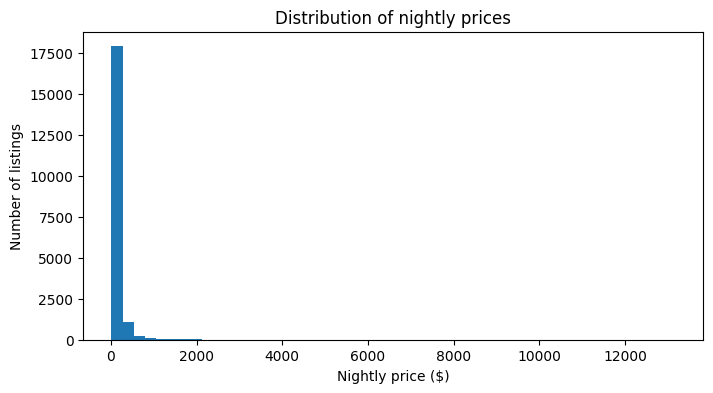

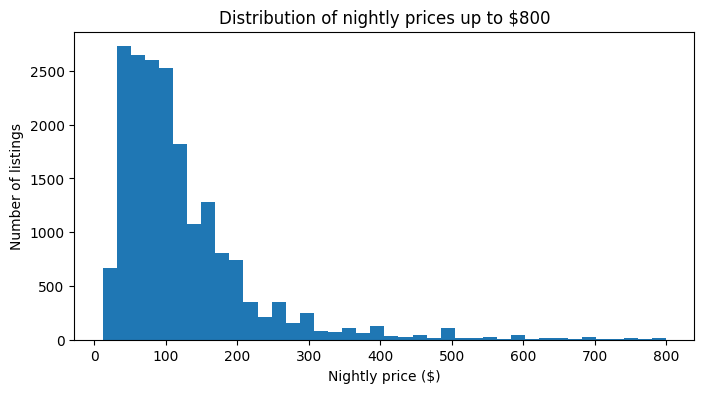

In [ ]:
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 4))
plt.hist(data["price"], bins=50)
plt.title("Distribution of nightly prices")
plt.xlabel("Nightly price ($)")
plt.ylabel("Number of listings")
plt.show()

data_plot = data[data["price"] <= 800]

plt.figure(figsize=(8, 4))
plt.hist(data_plot["price"], bins=40)
plt.title("Distribution of nightly prices up to $800")
plt.xlabel("Nightly price ($)")
plt.ylabel("Number of listings")
plt.show()

The distribution is right-skewed: most listings have relatively low prices, while a few are much more expensive. These high values increase the mean to about 141, compared with a median of 100.

### 5.2. Room types

,count
room_type,
Entire home/apt,12240
Private room,6693
Shared room,347
Hotel room,63


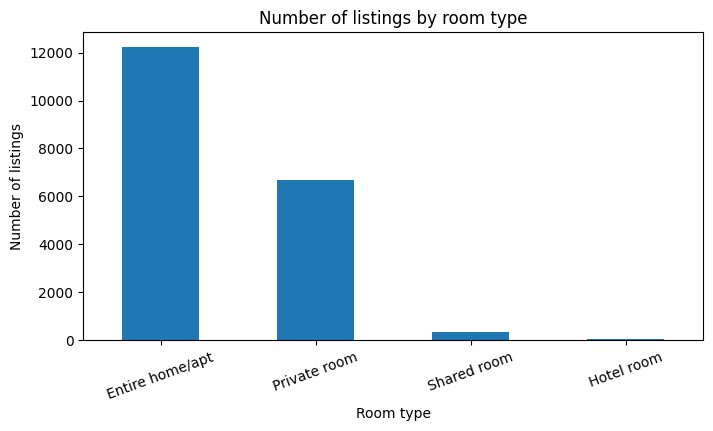

In [ ]:
display(data["room_type"].value_counts())

data["room_type"].value_counts().plot(kind="bar", figsize=(8, 4))
plt.title("Number of listings by room type")
plt.xlabel("Room type")
plt.ylabel("Number of listings")
plt.xticks(rotation=20)
plt.show()

Entire homes or apartments are the largest category, with 12,240 listings, followed by 6,693 private rooms. Shared rooms and hotel rooms are much less common, so classification accuracy alone could hide poor results for these smaller classes.

### 5.3. Prices by room type

We compare median prices across room types. The median is useful here because it is less affected by very expensive listings than the mean.

In [ ]:
import numpy as np

results = []

for room in data["room_type"].value_counts().index:
    prices = data[data["room_type"] == room]["price"]

    results.append({
        "Room type": room,
        "Median price": np.median(prices)
    })

display(pd.DataFrame(results))

,Room type,Median price
0,Entire home/apt,128.0
1,Private room,57.0
2,Shared room,34.0
3,Hotel room,89.0


Entire homes or apartments have a median price of 128 dollars, compared with 57 dollars for private rooms and 34 dollars for shared rooms. Room type is therefore associated with substantial price differences.

### 5.4. Relationships between numerical variables

We calculate correlations between numerical variables without missing values. We also plot price against guest capacity to examine their relationship.

,price,accommodates,number_of_reviews,latitude,longitude
price,1.000,0.259,-0.016,-0.078,0.009
accommodates,0.259,1.000,0.078,-0.101,-0.008
number_of_reviews,-0.016,0.078,1.000,-0.126,0.008
latitude,-0.078,-0.101,-0.126,1.000,0.296
longitude,0.009,-0.008,0.008,0.296,1.000


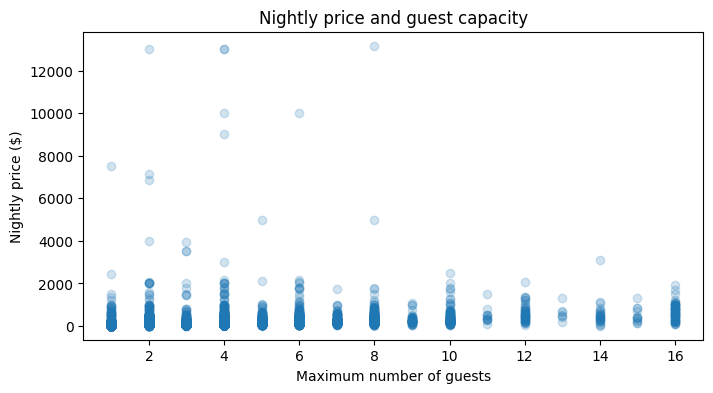

In [ ]:
columns = [
    "price", "accommodates", "number_of_reviews",
    "latitude", "longitude"
]

correlations = np.corrcoef([
    data["price"],
    data["accommodates"],
    data["number_of_reviews"],
    data["latitude"],
    data["longitude"]
])

display(pd.DataFrame(
    correlations,
    index=columns,
    columns=columns
).round(3))

plt.figure(figsize=(8, 4))
plt.scatter(data["accommodates"], data["price"], alpha=0.2)
plt.title("Nightly price and guest capacity")
plt.xlabel("Maximum number of guests")
plt.ylabel("Nightly price ($)")
plt.show()

Price and guest capacity have a positive correlation of about 0.259, but prices vary widely for the same capacity. The number of reviews has almost no linear correlation with price, and correlation does not establish causation.

### 5.5. Location of listings

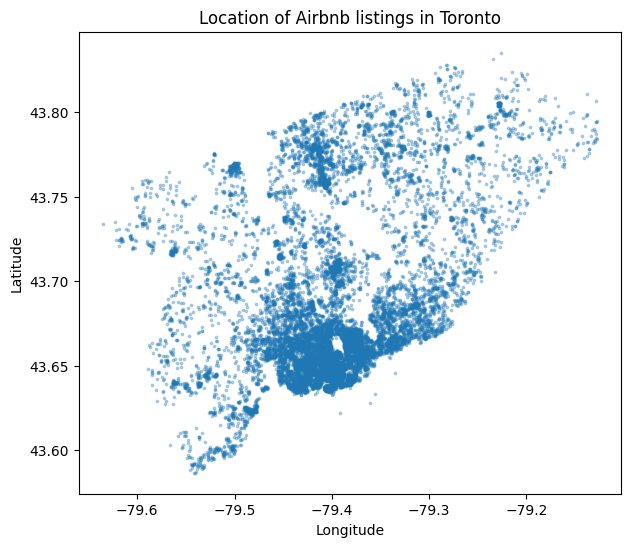

In [ ]:
plt.figure(figsize=(7, 6))
plt.scatter(data["longitude"], data["latitude"], s=3, alpha=0.3)
plt.title("Location of Airbnb listings in Toronto")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

The coordinates allow us to examine the geographical distribution of listings. However, weak correlations between price and individual coordinates do not rule out more complex differences between neighbourhoods.

## 6. Experimental protocol and feature selection

We define the input variables and evaluation procedure before training the models. Identifiers, names, URLs, and descriptions are excluded from the predictors.

We use numerical variables for clustering and regression, and predict `room_type` for classification. Guest capacity, bedrooms, and beds are discrete counts used as additional predictors in the supervised models.

| Analysis | Input variables | Target |
|---|---|---|
| K-means and AHC | Price, latitude, longitude, reviews per month | No target |
| Simple linear regression | Reviews per month | Price |
| Multiple linear regression | Reviews per month, latitude, longitude, guest capacity, bedrooms, beds | Price |
| KNN | Price, latitude, longitude, reviews per month, guest capacity, bedrooms, beds | Room type |

In [ ]:
cluster_columns = [
    "price", "latitude", "longitude", "reviews_per_month"
]

simple_columns = ["reviews_per_month"]

regression_columns = [
    "reviews_per_month", "latitude", "longitude",
    "accommodates", "bedrooms", "beds"
]

classification_columns = [
    "price", "latitude", "longitude", "reviews_per_month",
    "accommodates", "bedrooms", "beds"
]

The simple regression will test whether review frequency helps explain price; a strong relationship is not assumed. The multiple regression adds location and accommodation characteristics to assess whether they improve predictions.

# 6.2. Training and test sets

We reserve 30% of the listings for final testing and use 70% for training and model selection. Stratification keeps approximately the same room-type proportions in both sets, while `random_state=42` makes the split reproducible.

In [ ]:
from sklearn.model_selection import train_test_split

train_data, test_data = train_test_split(
    data,
    test_size=0.30,
    random_state=42,
    stratify=data["room_type"]
)

print("Training listings:", train_data.shape[0])
print("Test listings:", test_data.shape[0])

Training listings: 13540
Test listings: 5803


# 6.3. Preparing the inputs and targets




In [ ]:
X_train_simple = train_data[simple_columns]
X_test_simple = test_data[simple_columns]

X_train_reg = train_data[regression_columns]
X_test_reg = test_data[regression_columns]

y_train_reg = train_data["price"]
y_test_reg = test_data["price"]

In [ ]:
X_train_knn = train_data[classification_columns]
X_test_knn = test_data[classification_columns]

y_train_knn = train_data["room_type"]
y_test_knn = test_data["room_type"]

X_cluster = data[cluster_columns]

Both regressions use the same training and test listings for a fair comparison. Clustering is exploratory and uses a separate input table without target labels.

# 6.4. Missing values and scaling


We will replace missing numerical values with training medians using `SimpleImputer`. For KNN, preprocessing will be included in a pipeline so that imputation and standardization are fitted separately within each training fold.

K-means and AHC will use the same imputed and standardized observations because both methods depend on distances. If AHC requires a smaller sample, we will compare both algorithms on that same sample.

# 6.5. Model comparison


We will compare KNN settings using five-fold stratified cross-validation on the training set. The test set will only be used after selecting the final configuration.

| Models | Comparison criteria |
|---|---|
| K-means and AHC | Silhouette score, Davies–Bouldin index, cluster profiles |
| Simple and multiple regression | MSE and R² |
| KNN | Macro F1-score, accuracy, precision, recall, confusion matrix |

Macro F1 gives equal importance to each room type, including the smaller classes. We will compare several parameter settings and explain the final choices.

In [ ]:
from sklearn.model_selection import StratifiedKFold

cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

## 7. K-means clustering

We use K-means to group listings according to price, location, and review frequency. We select a reproducible sample of 2,000 listings, which will also be used for hierarchical clustering.

In [ ]:
cluster_data, _ = train_test_split(
    data,
    train_size=2000,
    random_state=42
)

X_cluster = cluster_data[cluster_columns]

print("Number of listings:", X_cluster.shape[0])
display(X_cluster.head())

Number of listings: 2000


,price,latitude,longitude,reviews_per_month
5978,250.0,43.66528,-79.38026,0.03
2196,45.0,43.71578,-79.56555,1.37
14089,85.0,43.76824,-79.34936,NaN
19237,44.0,43.65620,-79.39514,NaN
17757,110.0,43.64180,-79.40093,NaN


# 7.1. Preparing the data


We replace missing values with the median and standardize the variables. Standardization prevents variables with larger numerical scales, such as price, from dominating the distances.

In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler

imputer_cluster = SimpleImputer(strategy="median")
X_filled = imputer_cluster.fit_transform(X_cluster)

scaler_cluster = StandardScaler()
X_scaled = scaler_cluster.fit_transform(X_filled)

# 7.2. Elbow method


We test one to nine clusters and plot the within-cluster inertia. We look for a point where adding clusters produces a smaller improvement.

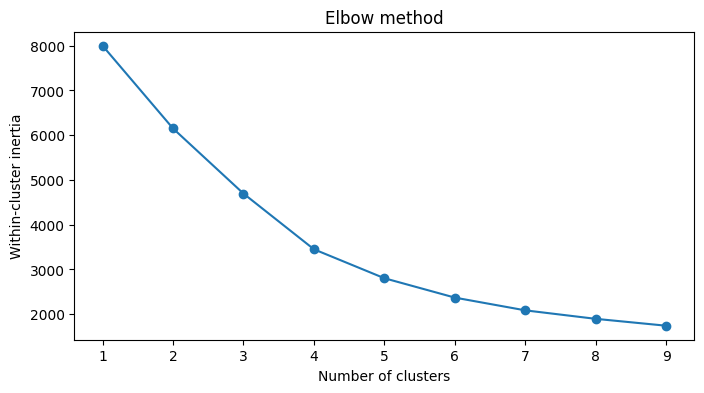

In [ ]:
from sklearn.cluster import KMeans

inertias = []
k_values = range(1, 10)

for k in k_values:
    model = KMeans(
        n_clusters=k,
        random_state=42,
        n_init=10
    )
    model.fit(X_scaled)
    inertias.append(model.inertia_)

plt.figure(figsize=(8, 4))
plt.plot(list(k_values), inertias, marker="o")
plt.title("Elbow method")
plt.xlabel("Number of clusters")
plt.ylabel("Within-cluster inertia")
plt.xticks(list(k_values))
plt.show()

# 7.3. Comparing configurations


We compare different numbers of clusters and two initialization methods. Higher silhouette scores and lower Davies–Bouldin indices indicate better separation and compactness.

In [ ]:
from sklearn.metrics import silhouette_score, davies_bouldin_score

results = []
best_score = -1

for k in range(2, 10):
    for initialization in ["k-means++", "random"]:
        model = KMeans(
            n_clusters=k,
            init=initialization,
            n_init=10,
            random_state=42
        )

        model.fit(X_scaled)

        silhouette = silhouette_score(X_scaled, model.labels_)
        davies = davies_bouldin_score(X_scaled, model.labels_)

        results.append({
            "K": k,
            "Initialization": initialization,
            "Silhouette": silhouette,
            "Davies-Bouldin": davies
        })

        if silhouette > best_score:
            best_score = silhouette
            kmeans = model

comparison = pd.DataFrame(results)
display(comparison.sort_values("Silhouette", ascending=False))

,K,Initialization,Silhouette,Davies-Bouldin
5,4,random,0.430085,0.805096
4,4,k-means++,0.430085,0.805096
9,6,random,0.396856,0.836099
8,6,k-means++,0.396753,0.836102
3,3,random,0.389636,0.902333
2,3,k-means++,0.389636,0.902333
0,2,k-means++,0.382282,1.183428
1,2,random,0.382282,1.183428
14,9,k-means++,0.377825,0.714733
6,5,k-means++,0.375747,0.877492


# 7.4. Examining the selected configuration

We first examine the configuration with the highest silhouette score. This is a candidate choice: we also need to consider the elbow curve, cluster sizes, and whether the groups are meaningful.


In [ ]:
print("Number of clusters:", kmeans.n_clusters)
print("Initialization:", kmeans.init)
print("Silhouette score:", best_score)

cluster_data["Cluster"] = kmeans.labels_

display(
    cluster_data["Cluster"].value_counts().sort_index()
)

display(
    cluster_data.groupby("Cluster")[cluster_columns].mean().round(2)
)

Number of clusters: 4
Initialization: k-means++
Silhouette score: 0.43008473198369646


,count
Cluster,
0,1399
1,422
2,177
3,2


,price,latitude,longitude,reviews_per_month
Cluster,,,,
0,148.64,43.66,-79.42,0.78
1,104.87,43.76,-79.34,0.81
2,121.84,43.66,-79.40,5.07
3,9924.00,43.72,-79.41,0.53


K-means selects four clusters, with a silhouette score of 0.430 and a Davies–Bouldin index of 0.805. Their sizes are 1,399, 422, 177, and 2 listings, showing that one group contains only extreme observations.

Cluster 1 is located further north on average, while cluster 2 has a higher review frequency, averaging 5.07 reviews per month among available values. Cluster 3 contains two exceptionally expensive listings with an average price of $9,924.

# 7.5. Visualizing the clusters

We display the clusters using geographical coordinates and the relationship between price and review frequency. These plots show only two variables at a time, while the clustering uses all four.


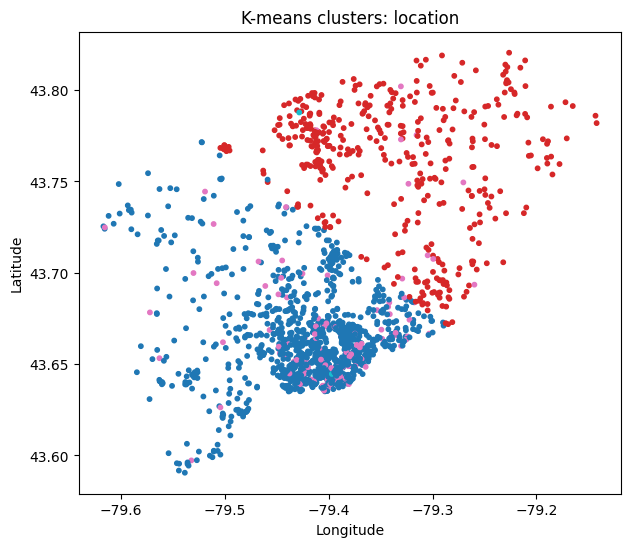

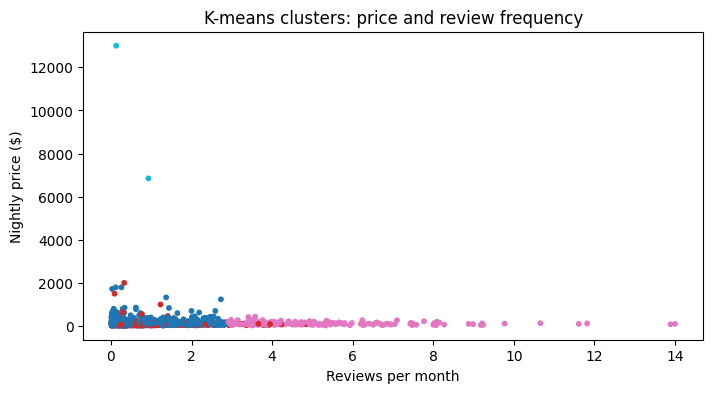

In [ ]:
plt.figure(figsize=(7, 6))
plt.scatter(
    cluster_data["longitude"],
    cluster_data["latitude"],
    c=kmeans.labels_,
    cmap="tab10",
    s=10
)
plt.title("K-means clusters: location")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

plt.figure(figsize=(8, 4))
plt.scatter(
    cluster_data["reviews_per_month"],
    cluster_data["price"],
    c=kmeans.labels_,
    cmap="tab10",
    s=10
)
plt.title("K-means clusters: price and review frequency")
plt.xlabel("Reviews per month")
plt.ylabel("Nightly price ($)")
plt.show()

## 8. Agglomerative Hierarchical Clustering

We apply hierarchical clustering to the same standardized data used for K-means. This method starts with individual observations and progressively merges them into groups.

# 8.1. Dendrogram

We build a dendrogram using Ward linkage, which merges groups by minimizing the increase in within-cluster inertia. Only the last 20 groups are displayed to keep the graph readable.

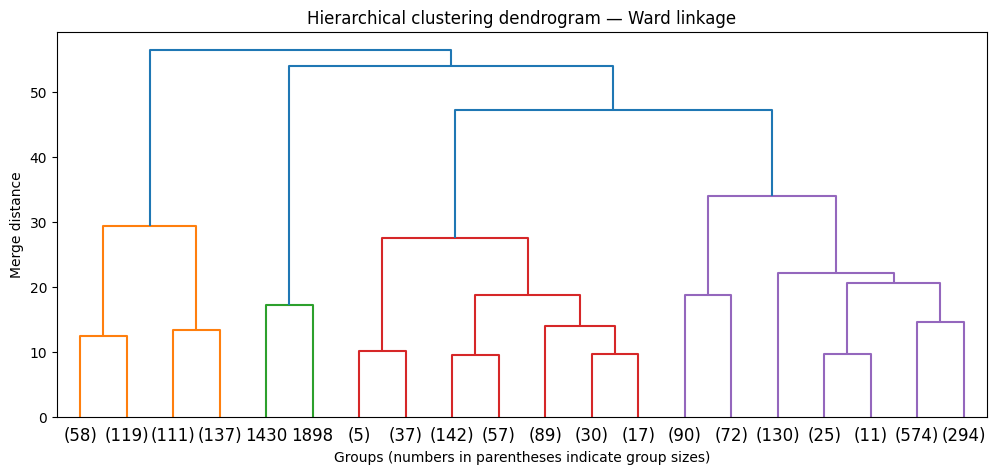

In [ ]:
from scipy.cluster.hierarchy import linkage, dendrogram

Z = linkage(X_scaled, method="ward")

plt.figure(figsize=(12, 5))
dendrogram(
    Z,
    truncate_mode="lastp",
    p=20
)
plt.title("Hierarchical clustering dendrogram — Ward linkage")
plt.xlabel("Groups (numbers in parentheses indicate group sizes)")
plt.ylabel("Merge distance")
plt.show()

# 8.2. Comparing configurations

We compare two to nine clusters using Ward, complete, and average linkage with Euclidean distance. We evaluate each configuration using the silhouette score and Davies–Bouldin index.


In [ ]:
from sklearn.cluster import AgglomerativeClustering
from sklearn.metrics import silhouette_score, davies_bouldin_score

results_ahc = []
best_score_ahc = -1

for k in range(2, 10):
    for method in ["ward", "complete", "average"]:
        model = AgglomerativeClustering(
            n_clusters=k,
            linkage=method
        )

        model.fit(X_scaled)

        silhouette = silhouette_score(X_scaled, model.labels_)
        davies = davies_bouldin_score(X_scaled, model.labels_)

        results_ahc.append({
            "K": k,
            "Linkage": method,
            "Silhouette": silhouette,
            "Davies-Bouldin": davies
        })

        if silhouette > best_score_ahc:
            best_score_ahc = silhouette
            ahc = model

comparison_ahc = pd.DataFrame(results_ahc)

display(
    comparison_ahc.sort_values("Silhouette", ascending=False)
)

,K,Linkage,Silhouette,Davies-Bouldin
1,2,complete,0.918784,0.375499
2,2,average,0.918784,0.375499
5,3,average,0.881749,0.069207
4,3,complete,0.881749,0.069207
8,4,average,0.738934,0.187512
7,4,complete,0.536417,0.359309
11,5,average,0.533795,0.406388
14,6,average,0.458474,0.430238
17,7,average,0.433130,0.512072
20,8,average,0.426620,0.493986


# 8.3. Examining the selected configuration


We first examine the configuration with the highest silhouette score. We also inspect group sizes and characteristics, since a high score may result from separating a few extreme listings.

In [ ]:
print("Number of clusters:", ahc.n_clusters)
print("Linkage:", ahc.linkage)
print("Silhouette score:", best_score_ahc)

cluster_data["Cluster_AHC"] = ahc.labels_

display(
    cluster_data["Cluster_AHC"].value_counts().sort_index()
)

display(
    cluster_data.groupby("Cluster_AHC")[cluster_columns].mean().round(2)
)

Number of clusters: 2
Linkage: complete
Silhouette score: 0.9187837025517384


,count
Cluster_AHC,
0,2
1,1998


,price,latitude,longitude,reviews_per_month
Cluster_AHC,,,,
0,9924.00,43.72,-79.41,0.53
1,137.02,43.68,-79.40,1.27


AHC selects complete linkage with two clusters, obtaining a silhouette score of 0.919 and a Davies–Bouldin index of 0.375. However, it separates two extremely expensive listings from the remaining 1,998, rather than identifying several substantial rental profiles.

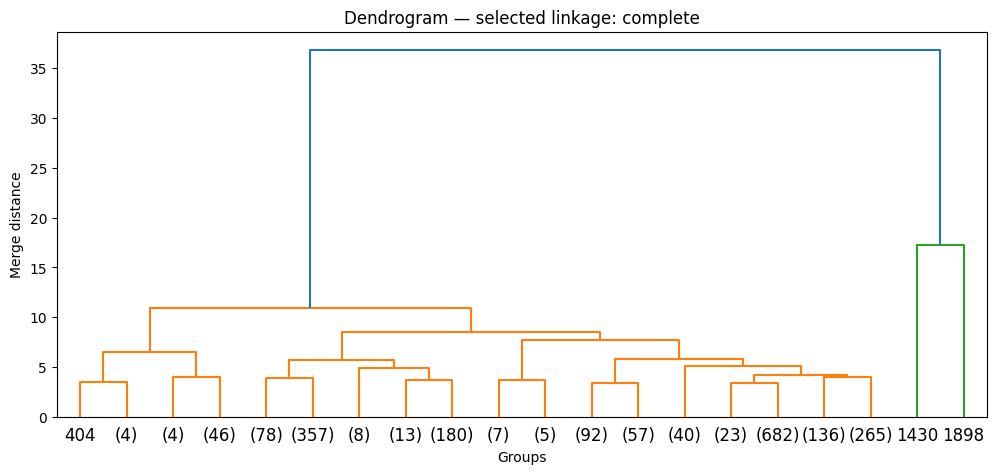

In [ ]:
Z_selected = linkage(X_scaled, method=ahc.linkage)

plt.figure(figsize=(12, 5))
dendrogram(
    Z_selected,
    truncate_mode="lastp",
    p=20
)
plt.title("Dendrogram — selected linkage: " + ahc.linkage)
plt.xlabel("Groups")
plt.ylabel("Merge distance")
plt.show()

# 8.4. Visualizing the clusters

We visualize the groups using the same variables as in the K-means plots. Cluster numbers are arbitrary, so matching numbers or colours across the two methods do not necessarily represent the same listings.

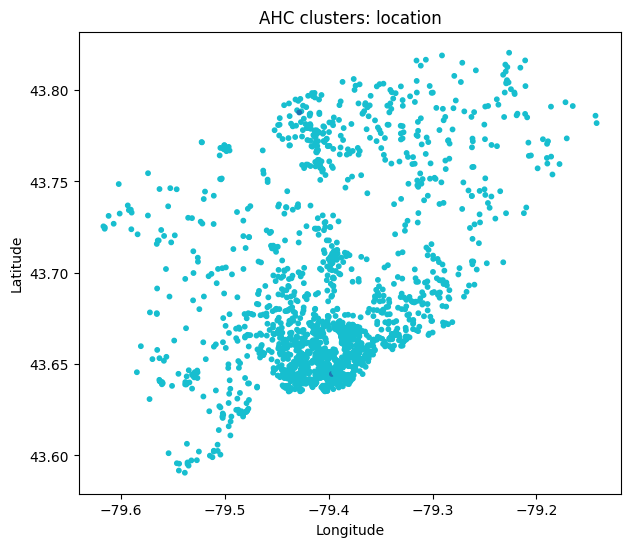

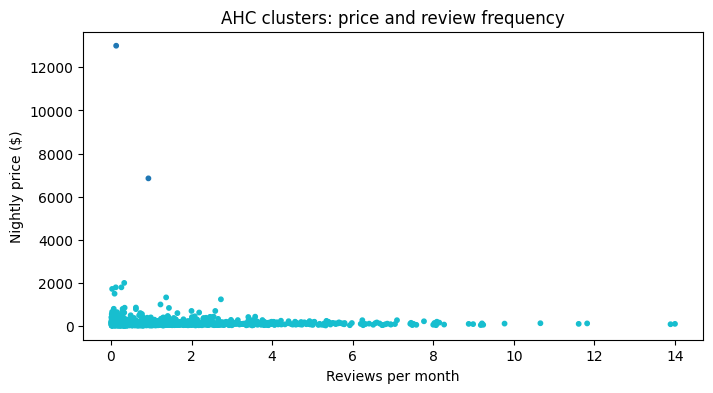

In [ ]:
plt.figure(figsize=(7, 6))
plt.scatter(
    cluster_data["longitude"],
    cluster_data["latitude"],
    c=ahc.labels_,
    cmap="tab10",
    s=10
)
plt.title("AHC clusters: location")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

plt.figure(figsize=(8, 4))
plt.scatter(
    cluster_data["reviews_per_month"],
    cluster_data["price"],
    c=ahc.labels_,
    cmap="tab10",
    s=10
)
plt.title("AHC clusters: price and review frequency")
plt.xlabel("Reviews per month")
plt.ylabel("Nightly price ($)")
plt.show()

## 9. Comparison of clustering methods

We compare K-means and AHC on the same 2,000 listings, using identical variables and preprocessing. We examine quality scores, cluster sizes, and group characteristics.

# 9.1. Comparing scores



In [ ]:
results_clustering = pd.DataFrame([
    {
        "Method": "K-means",
        "Clusters": kmeans.n_clusters,
        "Setting": kmeans.init,
        "Silhouette": silhouette_score(X_scaled, kmeans.labels_),
        "Davies-Bouldin": davies_bouldin_score(
            X_scaled, kmeans.labels_
        )
    },
    {
        "Method": "AHC",
        "Clusters": ahc.n_clusters,
        "Setting": ahc.linkage,
        "Silhouette": silhouette_score(X_scaled, ahc.labels_),
        "Davies-Bouldin": davies_bouldin_score(
            X_scaled, ahc.labels_
        )
    }
])

display(results_clustering.round(3))

,Method,Clusters,Setting,Silhouette,Davies-Bouldin
0,K-means,4,k-means++,0.430,0.805
1,AHC,2,complete,0.919,0.375


A higher silhouette score indicates better separation relative to within-cluster distances, while a lower Davies–Bouldin index is preferable. These results compare the selected configurations, which may use different numbers of clusters.

# 9.2. Comparing cluster sizes




In [ ]:
sizes_kmeans = cluster_data["Cluster"].value_counts()
sizes_ahc = cluster_data["Cluster_AHC"].value_counts()

sizes = pd.DataFrame([
    {
        "Method": "K-means",
        "Smallest cluster": sizes_kmeans.min(),
        "Largest cluster": sizes_kmeans.max()
    },
    {
        "Method": "AHC",
        "Smallest cluster": sizes_ahc.min(),
        "Largest cluster": sizes_ahc.max()
    }
])

display(sizes)

,Method,Smallest cluster,Largest cluster
0,K-means,2,1399
1,AHC,2,1998


We check whether the methods produce several substantial groups or mainly isolate a few unusual listings. Unequal cluster sizes are not necessarily wrong, but very small groups require closer examination.

# 9.3. Comparing group characteristics




AHC achieves better numerical scores, but its selected partition mainly isolates two extreme listings. We prefer the four-cluster K-means solution for describing rental profiles, while acknowledging that it also contains a two-listing extreme-price cluster.

## 10. Simple and multiple linear regression

# 10.1. Preparing the data


We replace missing values using medians calculated on the training set only. The same values are then used to transform the test set.

In [ ]:
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error

imputer_simple = SimpleImputer(strategy="median")

X_train_simple_filled = imputer_simple.fit_transform(X_train_simple)
X_test_simple_filled = imputer_simple.transform(X_test_simple)

imputer_reg = SimpleImputer(strategy="median")

X_train_reg_filled = imputer_reg.fit_transform(X_train_reg)
X_test_reg_filled = imputer_reg.transform(X_test_reg)

# 10.2. Simple linear regression

The simple model uses `reviews_per_month` to predict price. Its slope represents the predicted price difference associated with one additional review per month.


In [ ]:
simple_model = LinearRegression()
simple_model.fit(X_train_simple_filled, y_train_reg)

y_pred_simple = simple_model.predict(X_test_simple_filled)

print("Intercept:", simple_model.intercept_)
print("Reviews per month coefficient:", simple_model.coef_[0])

Intercept: 143.17759857318111
Reviews per month coefficient: -1.9225851346271956


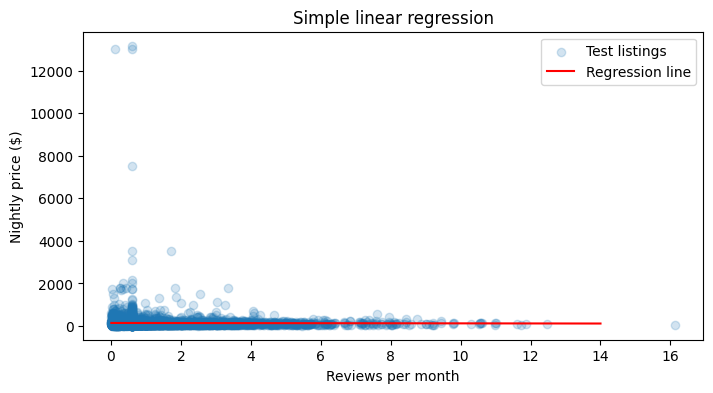

In [ ]:
x_line = np.array([
    [X_train_simple_filled.min()],
    [X_train_simple_filled.max()]
])

plt.figure(figsize=(8, 4))
plt.scatter(
    X_test_simple_filled,
    y_test_reg,
    alpha=0.2,
    label="Test listings"
)
plt.plot(
    x_line,
    simple_model.predict(x_line),
    color="red",
    label="Regression line"
)
plt.title("Simple linear regression")
plt.xlabel("Reviews per month")
plt.ylabel("Nightly price ($)")
plt.legend()
plt.show()

The fitted equation is: predicted price = 143.18 − 1.92 × reviews per month. The model therefore estimates a small negative association between review frequency and nightly price.

# 10.3. Multiple linear regression


The multiple model adds latitude, longitude, guest capacity, bedrooms, and beds. Each coefficient describes a predicted price difference while holding the other predictors constant; it does not establish causation.

In [ ]:
multiple_model = LinearRegression()
multiple_model.fit(X_train_reg_filled, y_train_reg)

y_pred_multiple = multiple_model.predict(X_test_reg_filled)

print("Intercept:", multiple_model.intercept_)

coefficients = pd.DataFrame({
    "Variable": regression_columns,
    "Coefficient": multiple_model.coef_
})

display(coefficients.round(3))

Intercept: 29964.17641284589


,Variable,Coefficient
0,reviews_per_month,-8.025
1,latitude,-457.188
2,longitude,125.594
3,accommodates,26.172
4,bedrooms,34.905
5,beds,-0.276


Holding the other predictors constant, one additional guest place is associated with a predicted price increase of 26.17 dollar , and one additional bedroom with 34.91 dollar. These coefficients describe conditional associations, not causal effects.

# 10.4. Comparing performance

We compare both models on the same test listings using MSE and R². Lower MSE and higher R² are preferable; a negative test R² means the model performs worse than predicting the test-set mean.

In [ ]:
results_regression = pd.DataFrame({
    "Model": ["Simple regression", "Multiple regression"],
    "Training R²": [
        simple_model.score(X_train_simple_filled, y_train_reg),
        multiple_model.score(X_train_reg_filled, y_train_reg)
    ],
    "Test R²": [
        simple_model.score(X_test_simple_filled, y_test_reg),
        multiple_model.score(X_test_reg_filled, y_test_reg)
    ],
    "Test MSE": [
        mean_squared_error(y_test_reg, y_pred_simple),
        mean_squared_error(y_test_reg, y_pred_multiple)
    ]
})

display(results_regression.round(3))

,Model,Training R²,Test R²,Test MSE
0,Simple regression,0.000,0.00,121839.090
1,Multiple regression,0.091,0.06,114587.964


The multiple model reduces test MSE from 121,839.09 to 114,587.96, an improvement of about 6%. However, its test R² is only 0.060, compared with approximately zero for the simple model, so price prediction remains weak.

# 10.5. Observed and predicted prices

We compare observed prices with predictions from the multiple model. Points closer to the reference line indicate more accurate predictions.

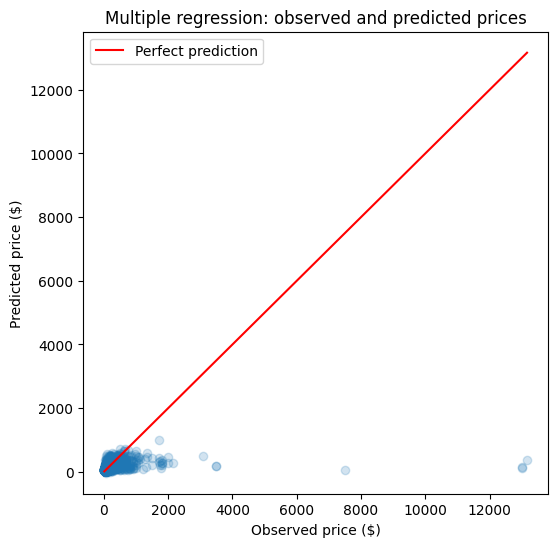

In [ ]:
limits = [y_test_reg.min(), y_test_reg.max()]

plt.figure(figsize=(6, 6))
plt.scatter(y_test_reg, y_pred_multiple, alpha=0.2)
plt.plot(limits, limits, color="red", label="Perfect prediction")
plt.title("Multiple regression: observed and predicted prices")
plt.xlabel("Observed price ($)")
plt.ylabel("Predicted price ($)")
plt.legend()
plt.show()

## 11. Classification with KNN

We use KNN to predict room type from price, location, review frequency, and accommodation characteristics. We compare several configurations using cross-validation on the training set.

# 11.1. Preparing the model

We place imputation, standardization, and KNN in a pipeline. This ensures that preprocessing is fitted only on the training observations within each validation fold.

In [ ]:
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_validate

# 11.2. Comparing hyperparameters

We vary the number of neighbours, voting weights, and distance: Manhattan for `p=1` and Euclidean for `p=2`. We select the highest mean macro F1-score, which gives equal importance to each room type.

In [ ]:
results_knn = []
best_f1 = -1

for k in [3, 5, 7, 11, 15, 21, 31]:
    for weight in ["uniform", "distance"]:
        for p in [1, 2]:
            model = Pipeline(steps=[
                ("imputer", SimpleImputer(strategy="median")),
                ("scaler", StandardScaler()),
                ("classifier", KNeighborsClassifier(
                    n_neighbors=k,
                    weights=weight,
                    p=p
                ))
            ])

            scores = cross_validate(
                model,
                X_train_knn,
                y_train_knn,
                cv=cv,
                scoring={
                    "accuracy": "accuracy",
                    "f1": "f1_macro"
                },
                n_jobs=-1
            )

            mean_f1 = scores["test_f1"].mean()

            results_knn.append({
                "K": k,
                "Weights": weight,
                "P": p,
                "Mean accuracy": scores["test_accuracy"].mean(),
                "Mean macro F1": mean_f1,
                "F1 standard deviation": scores["test_f1"].std()
            })

            if mean_f1 > best_f1:
                best_f1 = mean_f1
                best_k = k
                best_weight = weight
                best_p = p
                knn = model

comparison_knn = pd.DataFrame(results_knn)

display(
    comparison_knn.sort_values(
        "Mean macro F1", ascending=False
    ).round(3)
)

,K,Weights,P,Mean accuracy,Mean macro F1,F1 standard deviation
10,7,distance,1,0.835,0.620,0.040
6,5,distance,1,0.829,0.612,0.039
2,3,distance,1,0.820,0.610,0.024
14,11,distance,1,0.839,0.601,0.021
11,7,distance,2,0.829,0.601,0.018
18,15,distance,1,0.840,0.600,0.023
7,5,distance,2,0.824,0.596,0.019
0,3,uniform,1,0.819,0.592,0.048
15,11,distance,2,0.831,0.591,0.021
22,21,distance,1,0.842,0.587,0.019


The selected configuration uses seven neighbours, distance-weighted voting, and Manhattan distance, with a mean validation macro F1-score of 0.620. This configuration maximizes macro F1 rather than accuracy, to give more importance to performance across all room types.

# 11.3. Training the selected model

After selecting the configuration using cross-validation, we fit it on the full training set. We then predict room types for the independent test set.

In [ ]:
print("Selected K:", best_k)
print("Selected weights:", best_weight)
print("Selected p:", best_p)
print("Mean validation macro F1:", best_f1)

knn.fit(X_train_knn, y_train_knn)

y_pred_knn = knn.predict(X_test_knn)

Selected K: 7
Selected weights: distance
Selected p: 1
Mean validation macro F1: 0.6198046498666715


# 11.4. Evaluating classification performance


We report precision, recall, and F1-score for each room type, together with overall accuracy. This helps us identify classes that are poorly predicted despite a good overall score.

In [ ]:
from sklearn.metrics import (
    classification_report,
    accuracy_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)

print(classification_report(
    y_test_knn,
    y_pred_knn,
    zero_division=0
))

print("Test accuracy:", accuracy_score(y_test_knn, y_pred_knn))

print(
    "Test macro F1:",
    f1_score(y_test_knn, y_pred_knn, average="macro")
)

                 precision    recall  f1-score   support

Entire home/apt       0.87      0.89      0.88      3672
     Hotel room       0.58      0.37      0.45        19
   Private room       0.77      0.76      0.77      2008
    Shared room       0.78      0.35      0.48       104

       accuracy                           0.84      5803
      macro avg       0.75      0.59      0.64      5803
   weighted avg       0.83      0.84      0.83      5803

Test accuracy: 0.8356022746855075
Test macro F1: 0.6446968607732554


KNN achieves 83.56% test accuracy and a macro F1-score of 0.645. Recall is much lower for hotel rooms and shared rooms, at approximately 37% and 35%, meaning that most listings in these classes are missed.

# 11.5. Confusion matrix

The confusion matrix shows actual room types in rows and predicted types in columns. Values outside the diagonal represent classification errors.


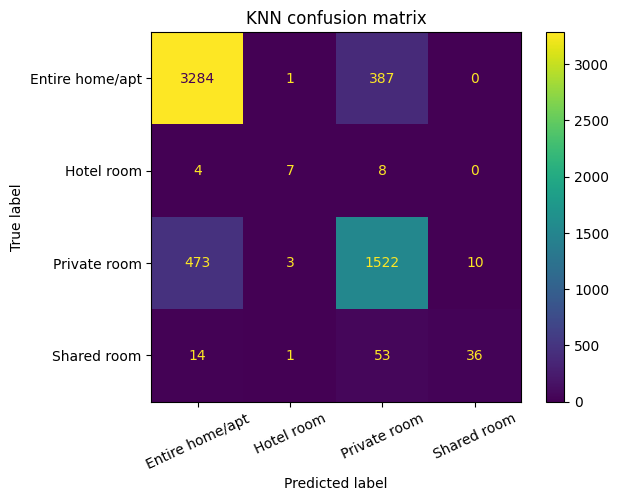

In [ ]:
room_types = sorted(y_train_knn.unique())

matrix = confusion_matrix(
    y_test_knn,
    y_pred_knn,
    labels=room_types
)

ConfusionMatrixDisplay(
    confusion_matrix=matrix,
    display_labels=room_types
).plot(xticks_rotation=25)

plt.title("KNN confusion matrix")
plt.show()

# 11.6. Comparing with a simple baseline

We compare KNN with a baseline that always predicts the most frequent room type in the training set. This checks whether KNN improves on a prediction that ignores listing characteristics.

In [ ]:
main_room = y_train_knn.value_counts().index[0]
baseline_predictions = [main_room] * len(y_test_knn)

results_classification = pd.DataFrame({
    "Model": ["Majority class", "KNN"],
    "Test accuracy": [
        accuracy_score(y_test_knn, baseline_predictions),
        accuracy_score(y_test_knn, y_pred_knn)
    ],
    "Test macro F1": [
        f1_score(
            y_test_knn,
            baseline_predictions,
            average="macro"
        ),
        f1_score(
            y_test_knn,
            y_pred_knn,
            average="macro"
        )
    ]
})

display(results_classification.round(3))

,Model,Test accuracy,Test macro F1
0,Majority class,0.633,0.194
1,KNN,0.836,0.645


KNN improves test accuracy from 63.28% for the majority-class baseline to 83.56%. Macro F1 also increases from 0.194 to 0.645, showing an improvement beyond predicting the most common room type.

## 12. Results, limitations and conclusion

We summarize the clustering, regression, and classification results below. Each task uses different evaluation criteria, so their scores cannot be compared directly.

# 12.1. Main findings

**Clustering:** K-means provides four groups that are more useful for describing rental profiles. AHC obtains higher quality scores, but mainly separates two extremely expensive listings from the rest.

**Regression:** Multiple regression improves test MSE, but its test R² of 0.060 indicates weak predictive performance. The simple model based on review frequency explains almost none of the test-price variation.

**Classification:** KNN achieves 83.56% accuracy and a macro F1-score of 0.645, outperforming the majority-class baseline. Hotel rooms and shared rooms remain difficult to identify.

# 12.2. Limitations

The dataset describes September 2020, during the COVID-19 pandemic, and does not represent the current market. Prices are advertised nightly prices, not actual earnings or confirmed booking prices.

Missing values and extreme prices may affect the models, while rare room types make classification more difficult. Clustering uses only 2,000 listings, and the groups depend on the selected variables and preprocessing.

# 12.3. Conclusion

The selected listing characteristics support useful room-type classification, but explain only a small share of price variation through linear regression. Clustering reveals differences in location and review frequency, while also showing how extreme prices can strongly influence the groups.

## 13. Source

The dataset comes from [Toronto Airbnb Dataset on Kaggle](https://www.kaggle.com/datasets/robinkongninglo/toronto-airbnb-dataset). We use `listings_sep_09_2020.csv`, containing 19,343 listings and 74 original columns.